In [2]:
!pip install requests beautifulsoup4 pandas lxml

In [3]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

url = "https://onlinesleepcalculator.com/sleep-calculator-by-age"

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

print("Status code:", response.status_code)

Status code: 200


In [4]:
tables = pd.read_html(response.text)

print("Number of tables found:", len(tables))

Number of tables found: 1


/tmp/ipykernel_1038/4081976331.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


In [5]:
for i, table in enumerate(tables):
    print(f"\nTable {i}")
    display(table)


Table 0


,Age Category,Age Range,Recommended Daily Sleep,Typical Nap Need,REM Sleep %
0,ð¶ Newborn,0 â 3 months,14 â 17 hours,3 â 5 naps/day,50% REM
1,ð¼ Infant,4 â 11 months,12 â 15 hours,2 â 3 naps/day,30 â 40% REM
2,ð§¸ Toddler,1 â 2 years,11 â 14 hours,1 â 2 naps/day,25% REM
3,ð¨ Preschooler,3 â 5 years,10 â 13 hours,0 â 1 nap/day,20 â 25% REM
4,ð School-Age Child,6 â 12 years,9 â 12 hours,Rarely required,20% REM
5,ð§ Teenager,13 â 17 years,8 â 10 hours,Optional 20m power nap,20% REM
6,ð Young Adult,18 â 25 years,7 â 9 hours,As needed for sleep debt,20% REM
7,ð§ Adult,26 â 64 years,7 â 9 hours,Optional 20m power nap,20% REM
8,ð´ Older Adult,65+ years,7 â 8 hours,30m early afternoon nap,15 â 20% REM


In [6]:
sleep_recommendations = tables[0][[
    "Age Category",
    "Age Range",
    "Recommended Daily Sleep"
]]

display(sleep_recommendations)

,Age Category,Age Range,Recommended Daily Sleep
0,ð¶ Newborn,0 â 3 months,14 â 17 hours
1,ð¼ Infant,4 â 11 months,12 â 15 hours
2,ð§¸ Toddler,1 â 2 years,11 â 14 hours
3,ð¨ Preschooler,3 â 5 years,10 â 13 hours
4,ð School-Age Child,6 â 12 years,9 â 12 hours
5,ð§ Teenager,13 â 17 years,8 â 10 hours
6,ð Young Adult,18 â 25 years,7 â 9 hours
7,ð§ Adult,26 â 64 years,7 â 9 hours
8,ð´ Older Adult,65+ years,7 â 8 hours


In [7]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/data_aquisition_excersises/Data AquIsition Project/bedtime_screentime_sleep_debt.csv")

display(df.head())

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [8]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

Minimum age: 18
Maximum age: 65


In [41]:
df.describe()

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,34.355647,59.250000,55.153882,0.467765,33.222471,35.701412,40.671471,6.266209,21.735741,19.105859,2.766000,3.794671
std,11.584259,36.931991,19.850550,0.498989,51.935645,20.819390,17.444914,1.446258,3.069377,2.546459,1.695407,2.685153
min,18.000000,1.000000,10.000000,0.000000,0.000000,0.000000,6.000000,3.200000,8.100000,9.600000,0.000000,1.000000
25%,25.000000,31.000000,42.000000,0.000000,0.000000,21.000000,28.200000,5.240000,19.700000,17.400000,2.000000,1.100000
50%,32.000000,51.000000,55.000000,0.000000,0.000000,35.000000,37.600000,6.330000,21.900000,19.100000,3.000000,3.200000
75%,42.000000,79.000000,69.000000,1.000000,55.000000,50.000000,49.700000,7.350000,23.900000,20.800000,4.000000,5.600000
max,65.000000,180.000000,100.000000,1.000000,250.000000,112.000000,123.300000,9.800000,28.000000,27.000000,7.000000,10.000000


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [43]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
occupation_type,0
chronotype,0
bedtime_phone_minutes,0
primary_bedtime_app,0
screen_brightness_pct,0
blue_light_filter_active,0
caffeine_post_5pm_mg,0


In [9]:
for i, table in enumerate(tables):
    print(f"Table {i}")
    display(table)

Table 0


,Age Category,Age Range,Recommended Daily Sleep,Typical Nap Need,REM Sleep %
0,ð¶ Newborn,0 â 3 months,14 â 17 hours,3 â 5 naps/day,50% REM
1,ð¼ Infant,4 â 11 months,12 â 15 hours,2 â 3 naps/day,30 â 40% REM
2,ð§¸ Toddler,1 â 2 years,11 â 14 hours,1 â 2 naps/day,25% REM
3,ð¨ Preschooler,3 â 5 years,10 â 13 hours,0 â 1 nap/day,20 â 25% REM
4,ð School-Age Child,6 â 12 years,9 â 12 hours,Rarely required,20% REM
5,ð§ Teenager,13 â 17 years,8 â 10 hours,Optional 20m power nap,20% REM
6,ð Young Adult,18 â 25 years,7 â 9 hours,As needed for sleep debt,20% REM
7,ð§ Adult,26 â 64 years,7 â 9 hours,Optional 20m power nap,20% REM
8,ð´ Older Adult,65+ years,7 â 8 hours,30m early afternoon nap,15 â 20% REM


In [10]:
sleep_recommendations = tables[0].iloc[6:9].copy()

display(sleep_recommendations)

,Age Category,Age Range,Recommended Daily Sleep,Typical Nap Need,REM Sleep %
6,ð Young Adult,18 â 25 years,7 â 9 hours,As needed for sleep debt,20% REM
7,ð§ Adult,26 â 64 years,7 â 9 hours,Optional 20m power nap,20% REM
8,ð´ Older Adult,65+ years,7 â 8 hours,30m early afternoon nap,15 â 20% REM


In [11]:
sleep_recommendations = sleep_recommendations[
    ["Age Category", "Age Range", "Recommended Daily Sleep"]
]

display(sleep_recommendations)

,Age Category,Age Range,Recommended Daily Sleep
6,ð Young Adult,18 â 25 years,7 â 9 hours
7,ð§ Adult,26 â 64 years,7 â 9 hours
8,ð´ Older Adult,65+ years,7 â 8 hours


As I was doing this I realised that the numbers for this column are too similar and wouldnt give me very interesting variations to work with so I decided to pivot and find a new website to scrape but this time I wanted to estimate the time people went to sleep at based on their recommended betime for their age and how much time each person spent on their phone before bed as I thought this would be a more interesting concept.

In [12]:
sleep_recommendations.to_csv(
    "sleep_recommendations.csv",
    index=False
)

In [13]:


url = "https://mymedicineadvisor.com/health/hours-of-sleep-by-age/"

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},

)

print("Status code:", response.status_code)

Status code: 200


In [14]:
tables = pd.read_html(response.text)

print("Number of tables found:", len(tables))

Number of tables found: 3


/tmp/ipykernel_1038/4081976331.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


This is just finding all of the tables on the website mymedicineadvisor

In [15]:
for i, table in enumerate(tables):
    print(f"Table {i}")
    display(table)

Table 0


,Age Group,Recommended Sleep Hours,Includes Naps?
0,Newborns (0–3 months),14–17 hours,Yes
1,Infants (4–12 months),12–16 hours,Yes
2,Toddlers (1–2 years),11–14 hours,Yes
3,Preschoolers (3–5 years),10–13 hours,Yes
4,School-age children (6–12 years),9–12 hours,No
5,Teenagers (13–17 years),8–10 hours,No
6,Young adults (18–25 years),7–9 hours,No
7,Adults (26–64 years),7–9 hours,No
8,Older adults (65+),7–8 hours,No


Table 1


,Age Group,Wake Time,Target Bedtime
0,School-age (6–12),7:00 AM,8:00–9:00 PM
1,Teenagers (13–17),7:00 AM,9:00–10:30 PM
2,Young adults (18–25),6:30 AM,9:30–11:00 PM
3,Adults (26–64),6:00 AM,10:00–11:00 PM
4,Older adults (65+),5:30–6:00 AM,9:30–10:30 PM


Table 2


,Symptom,Likely Cause,Recommended Action
0,Daytime fatigue lasting 3+ weeks,"Sleep apnea, insomnia disorder",See a primary care physician
1,Can’t fall asleep >30 min most nights,Chronic insomnia,Start with CBT-I (first-line treatment)
2,Waking 3+ times per night,"Fragmented sleep, apnea, anxiety",Rule out sleep apnea; evaluate anxiety
3,Need 10+ hours daily and still tired,"Hypersomnia, depression, thyroid",Neurological and metabolic evaluation
4,Loud snoring + gasping reported by partner,Obstructive sleep apnea,Urgent: sleep study (polysomnography)
5,Uncontrollable urge to move legs at night,Restless Leg Syndrome (RLS),Neurological evaluation


I then went on to print out all of these tables to see which is the one I originally found on the website to use which this tells me it was table one so now I am able to just use table one from now on as the rest dont relate to the variations I want to create.

In [16]:
sleep_table = tables[1].copy()

display(sleep_table)

,Age Group,Wake Time,Target Bedtime
0,School-age (6–12),7:00 AM,8:00–9:00 PM
1,Teenagers (13–17),7:00 AM,9:00–10:30 PM
2,Young adults (18–25),6:30 AM,9:30–11:00 PM
3,Adults (26–64),6:00 AM,10:00–11:00 PM
4,Older adults (65+),5:30–6:00 AM,9:30–10:30 PM


In [17]:
sleep_table = sleep_table.iloc[2:5].copy()

display(sleep_table)

,Age Group,Wake Time,Target Bedtime
2,Young adults (18–25),6:30 AM,9:30–11:00 PM
3,Adults (26–64),6:00 AM,10:00–11:00 PM
4,Older adults (65+),5:30–6:00 AM,9:30–10:30 PM


I then went back to look at my Kaggle dataset and put it into excel and went into the age column and removed all duplicated cells so that I could see how many ages there were in total and it came back with 18-64 year olds this correlated perfectly with the table on this website as they had  young adults, adults and older adults which matched the ages, so I was able to remove the first two rows as it was not relevent for my variations as they dont exist in my dataset.

In [18]:
sleep_table.to_csv("sleep_bedtime_recommendations.csv", index=False)

In [19]:
display(sleep_table)

,Age Group,Wake Time,Target Bedtime
2,Young adults (18–25),6:30 AM,9:30–11:00 PM
3,Adults (26–64),6:00 AM,10:00–11:00 PM
4,Older adults (65+),5:30–6:00 AM,9:30–10:30 PM


In [20]:
print(df.columns.tolist())

['user_id', 'age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score', 'sleep_debt_category']


I then just wanted to check the columns in my kaggle dataset just to see what headings I would be adding to it to keep it looking similar

In [21]:
def assign_age_group(age):
    if 18 <= age <= 25:
        return "Young adults (18–25)"
    elif 26 <= age <= 64:
        return "Adults (26–64)"
    elif age == 65:
        return "Older adults (65+)"
    else:
        return None

df["Age Group"] = df["age"].apply(assign_age_group)

display(df[["age", "Age Group"]].head(10))

,age,Age Group
0,29,Adults (26–64)
1,58,Adults (26–64)
2,41,Adults (26–64)
3,36,Adults (26–64)
4,23,Young adults (18–25)
5,23,Young adults (18–25)
6,20,Young adults (18–25)
7,49,Adults (26–64)
8,36,Adults (26–64)
9,40,Adults (26–64)


The ages in the kaggle dataset were specific and the ages in the table were split up into categories so before I could merge them together I had to make a common column that took all of the ages in the dataset and split them into young adults, adults and older adults so that they were the same this made me be able to match the two datasets in a column called age groups.

In [22]:
print(df["Age Group"].value_counts())

Age Group
Adults (26–64)          6228
Young adults (18–25)    2232
Older adults (65+)        40
Name: count, dtype: int64


I then checked to see how many people out of this dataset fit into each category. this is where I learned that there was mostl adults used and only 40 older adults so I had to make sure I took this into account when making my variations.

In [23]:
display(sleep_table)

,Age Group,Wake Time,Target Bedtime
2,Young adults (18–25),6:30 AM,9:30–11:00 PM
3,Adults (26–64),6:00 AM,10:00–11:00 PM
4,Older adults (65+),5:30–6:00 AM,9:30–10:30 PM


In [24]:
merged_df = df.merge(
    sleep_table,
    on="Age Group",
    how="left"
)

Once I had all of that I was then able to merge both of the datasets together based on age group it matches people aged 24 to young adults category and their estimated wake up time to be 6:30am. To keep all of the data from the original dataset I had to do a left merge which finds all of the matching data from my scraped dataset and adds the recommended sleep and wake up time to each persons row.

In [25]:
display(merged_df[[
    "age",
    "Age Group",
    "Wake Time",
    "Target Bedtime"
]].head(10))

,age,Age Group,Wake Time,Target Bedtime
0,29,Adults (26–64),6:00 AM,10:00–11:00 PM
1,58,Adults (26–64),6:00 AM,10:00–11:00 PM
2,41,Adults (26–64),6:00 AM,10:00–11:00 PM
3,36,Adults (26–64),6:00 AM,10:00–11:00 PM
4,23,Young adults (18–25),6:30 AM,9:30–11:00 PM
5,23,Young adults (18–25),6:30 AM,9:30–11:00 PM
6,20,Young adults (18–25),6:30 AM,9:30–11:00 PM
7,49,Adults (26–64),6:00 AM,10:00–11:00 PM
8,36,Adults (26–64),6:00 AM,10:00–11:00 PM
9,40,Adults (26–64),6:00 AM,10:00–11:00 PM


In [26]:
print("Original rows:", len(df))
print("Merged rows:", len(merged_df))

print(merged_df[["Wake Time", "Target Bedtime"]].isna().sum())

Original rows: 8500
Merged rows: 8500
Wake Time         0
Target Bedtime    0
dtype: int64


Then I just made sure that the merge worked by printing the merged table and checking the merged rows with the original rows to make sure non were dropped or missing.

First visualisation attempt: Comparing phone usage accross the three age groups.

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
age_phone_usage = merged_df.groupby("Age Group")["bedtime_phone_minutes"].mean()

print(age_phone_usage)

Age Group
Adults (26–64)          58.768786
Older adults (65+)      59.450000
Young adults (18–25)    60.589158
Name: bedtime_phone_minutes, dtype: float64


For this first part i looked to see the average phone usage before bed between each age group to see if there was any significant differences. From the outcome I learned that the average is very similar accross all age groups with young adults coming out to spend the most time on their phone but the difference between each age group is just over a minute.

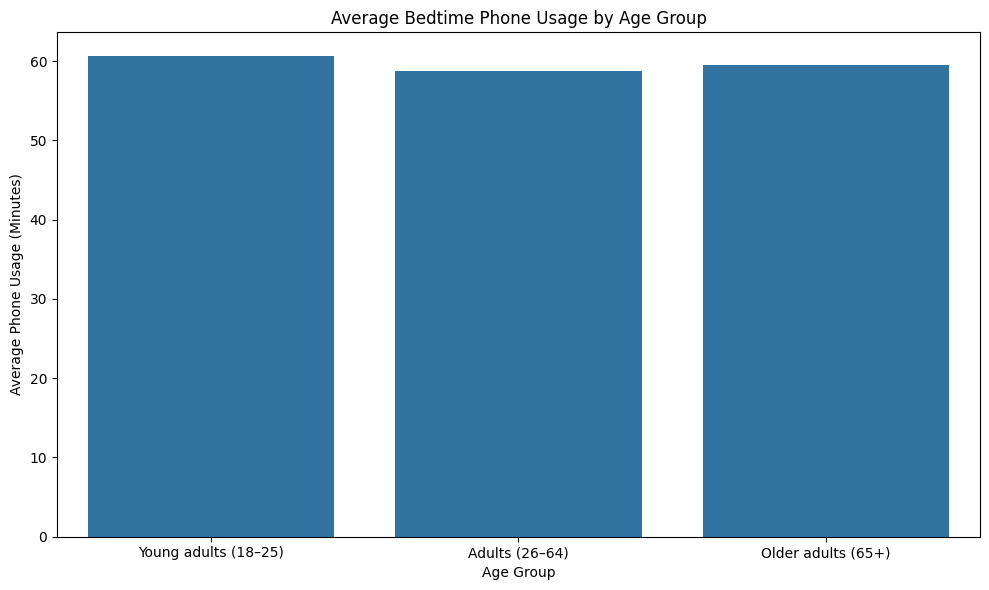

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=merged_df,
    x="Age Group",
    y="bedtime_phone_minutes",
    order=[
        "Young adults (18–25)",
        "Adults (26–64)",
        "Older adults (65+)"
    ],
    errorbar=None
)

plt.title("Average Bedtime Phone Usage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Phone Usage (Minutes)")
plt.tight_layout()
plt.show()

I then created a bar chart using seaborn to represent this.

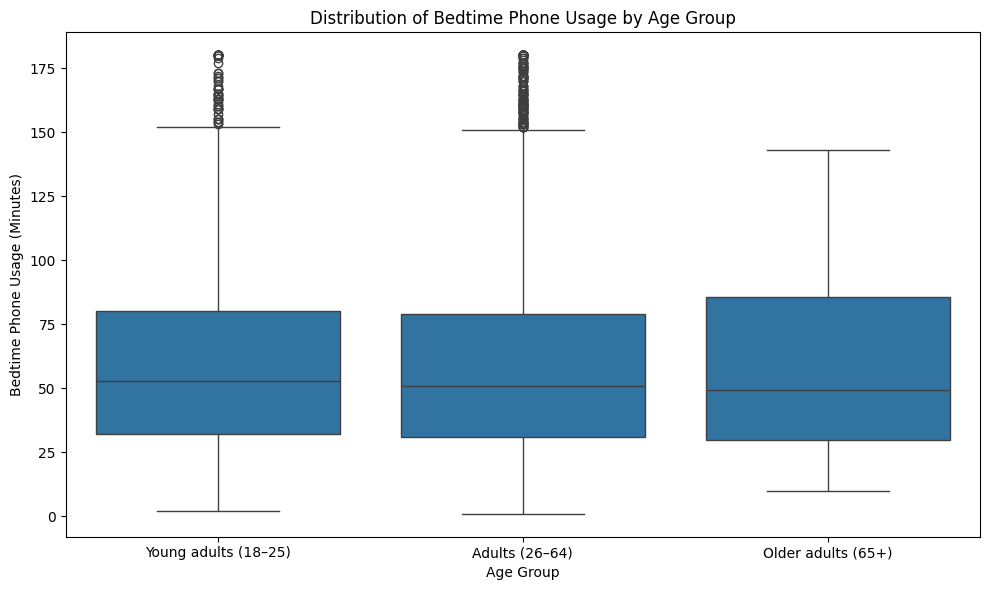

In [30]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=merged_df,
    x="Age Group",
    y="bedtime_phone_minutes",
    order=[
        "Young adults (18–25)",
        "Adults (26–64)",
        "Older adults (65+)"
    ]
)

plt.title("Distribution of Bedtime Phone Usage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Bedtime Phone Usage (Minutes)")
plt.tight_layout()
plt.show()

I then created a boxplot as this gives more information than the bar chart such as the median and also any outliers which I was unable to see in the bar chart. This was also similar although adults and young adults had many outliers who used their phone for over 150 minutes before bed but this may have had to do with the fact there was thousands of data entries for these ages and the older adults had only 40 and had no outliers.

In [31]:
wake_time_minutes = {
    "Young adults (18–25)": 390,
    "Adults (26–64)": 360,
    "Older adults (65+)": 345
}

merged_df["Wake Time Minutes"] = merged_df["Age Group"].map(wake_time_minutes)

I then started using data from my scraped dataset to estimate wakeup times of the individuals I was able to use the sleep_latency column which told me how long it took someone to fall asleep after using their phones in minutes this helped me find out their total sleep hours if they woke up at the estimated time. To be able to make calculations to find out what time someone went to bed at I needed to turn the time value into a numerical value. So after midnight which is 0 i calculated the time of the esimated wake up. So for young adults 6:30am is 390 minutes after midnight, for adults 6:00am is 360 minutes after midnight and as older adults was estimated to be between 5:30am and 6:00am i chose to do 5:45am as this was in the middle and this was 345 minutes after midnight so now all of the values are numeric and made it much easier for me to do calculations on it. By using map I was able to convert them.

In [32]:
merged_df["Estimated Bedtime Minutes"] = (
    merged_df["Wake Time Minutes"]
    - (merged_df["total_sleep_hours"] * 60)
    - merged_df["sleep_latency_min"]
) % 1440

I was then able to calculate the estimated bedtime by taking the estimated wakeup time in minutes and taking away the total sleep hours in minutes by multiplying by 60 and then taking away the sleep latency to get the estimated time a person went to bed at. I then used the modulo operator in python to convert the - times to postive as it was giving me -60 minutes so that meant someone went to bed at 11pm as its 60 minutes before bedtime but wanted all answers to be positive to work better so %1440 allows it to calculate after midnight and not before as there is 1140 minutes in a full day.

In [33]:
merged_df["Estimated Bedtime"] = pd.to_datetime(
    merged_df["Estimated Bedtime Minutes"], unit="m"
).dt.strftime("%I:%M %p")

I then created a new column in my dataset called estimated bedtime which told us each persons estimated bedtime based on the results of the calculations. I then had to turn it into a datetime format as before I was only working in minutes but now to see what time people were estimated to go to bed at I had to convert it into a time format. And for the calculations before to make sense it had to be in the unit m so that it wasnt confused with seconds or hours after midnight. To then display the time how I wanted I had to use strftime("%I:%M %p") which told python to display hours then minutes then am or pm on the 24 hour clock.

In [34]:
display(merged_df[[
    "age",
    "Age Group",
    "Wake Time",
    "total_sleep_hours",
    "sleep_latency_min",
    "Estimated Bedtime"
]].head(10))

,age,Age Group,Wake Time,total_sleep_hours,sleep_latency_min,Estimated Bedtime
0,29,Adults (26–64),6:00 AM,3.20,84.4,01:23 AM
1,58,Adults (26–64),6:00 AM,4.06,86.7,12:29 AM
2,41,Adults (26–64),6:00 AM,3.20,70.5,01:37 AM
3,36,Adults (26–64),6:00 AM,6.99,38.1,10:22 PM
4,23,Young adults (18–25),6:30 AM,4.58,32.3,01:22 AM
5,23,Young adults (18–25),6:30 AM,5.87,50.6,11:47 PM
6,20,Young adults (18–25),6:30 AM,4.43,36.2,01:28 AM
7,49,Adults (26–64),6:00 AM,5.94,60.2,11:03 PM
8,36,Adults (26–64),6:00 AM,8.00,28.2,09:31 PM
9,40,Adults (26–64),6:00 AM,4.70,53.7,12:24 AM


I then displayed the first 10 observations to make sure that it worked.

In [35]:
print(merged_df["Target Bedtime"].value_counts())

Target Bedtime
10:00–11:00 PM    6228
9:30–11:00 PM     2232
9:30–10:30 PM       40
Name: count, dtype: int64


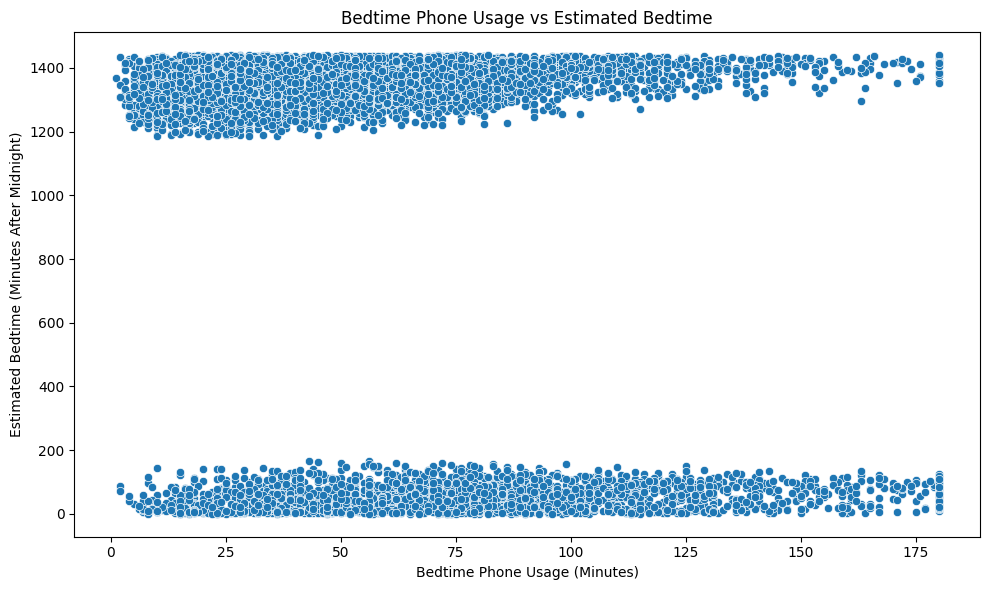

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=merged_df,
    x="bedtime_phone_minutes",
    y="Estimated Bedtime Minutes"
)

plt.title("Bedtime Phone Usage vs Estimated Bedtime")
plt.xlabel("Bedtime Phone Usage (Minutes)")
plt.ylabel("Estimated Bedtime (Minutes After Midnight)")

plt.tight_layout()
plt.show()

This was the first scatterplot i created which i knew didnt look right. I realised that it was the numbers after midnight that were cause the problem as it would see 1am as 60 as it was in minutes which was later than 11pm but was not showing this so I had to change it to make it look correct

In [37]:
merged_df["Adjusted Bedtime Minutes"] = merged_df["Estimated Bedtime Minutes"]

merged_df.loc[
    merged_df["Adjusted Bedtime Minutes"] < 720,
    "Adjusted Bedtime Minutes"
] += 1440

I then had to fix the bedtime minutes to make 1am later than 11pm. I used midday as the cutoff so 720 minutes after midnight and added 1440 minutes to that to add a day to it so 1 am would be 60 + 1440. so it would reflect that 1 am is later as ive now added a day to it.

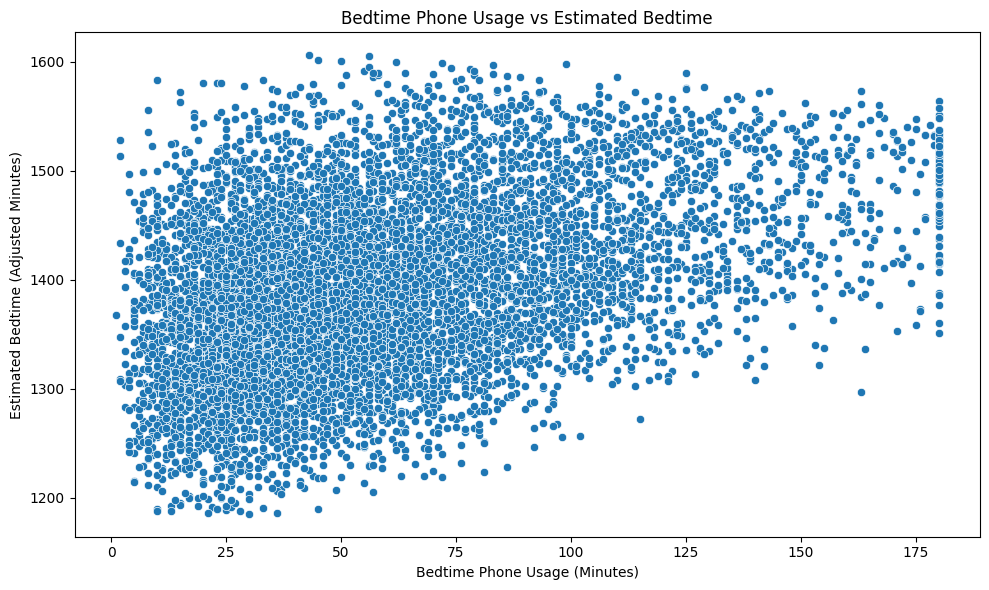

In [38]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=merged_df,
    x="bedtime_phone_minutes",
    y="Adjusted Bedtime Minutes"
)

plt.title("Bedtime Phone Usage vs Estimated Bedtime")
plt.xlabel("Bedtime Phone Usage (Minutes)")
plt.ylabel("Estimated Bedtime (Adjusted Minutes)")

plt.tight_layout()
plt.show()

This scatterplot worked a lot better as it represented the estimated bedtimes more accuarate. From this I could see that there was a very slight positive correlation with people going to bed later spend more time on there phone but as the points are widly spread the relationship doesnt appear to be particulary strong.

In [39]:
correlation = merged_df["bedtime_phone_minutes"].corr(
    merged_df["Adjusted Bedtime Minutes"]
)

print("Correlation:", correlation)

Correlation: 0.4163412727610062


By getting the correlation coefficient I was able to tell how to measure the relationship. As close to +1 is a stong relationship close to 0 is little to none and close to -1 is a strong negative relationship. As my correlation coefficient was 0.416 it is clear that there is a positive correlation but it is not particulary stong. Overall it shows that people who use there phone for longer typically seem to stay up later but is not a strong postitive so i tells us that phone usage may not be the only factor in why people stay up late.